In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

In [2]:
data_path = Path("../Data/Processed/dataco_cleaned.csv")

if not data_path.exists():
    raise FileNotFoundError(
        f"Processed dataset not found{data_path}\n"
    )

df = pd.read_csv(
    data_path,
    low_memory=False,
    parse_dates= [
        "order date (DateOrders)",
        "shipping date (DateOrders)"
    ],
)

print(f"loaded file: {data_path}")
print(f"rows:{len(df):,}")
print(f"columns: {df.shape[1]}")


loaded file: ../Data/Processed/dataco_cleaned.csv
rows:180,519
columns: 64


In [3]:

grain_check = pd.DataFrame({
    "metric": [
        "total_rows",
        "unique_order_items",
        "unique_orders",
        "duplicate_order_item_ids",
        "duplicate_full_rows"
    ],
    "value": [
        len(df),
        df["Order Item Id"].nunique(),
        df["Order Id"].nunique(),
        df["Order Item Id"].duplicated().sum(),
        df.duplicated().sum()
    ]
})

display(grain_check)


,metric,value
0,total_rows,180519
1,unique_order_items,180519
2,unique_orders,65752
3,duplicate_order_item_ids,0
4,duplicate_full_rows,0


In [4]:
delivery_summary = (
    df["delivery_timing"].value_counts(dropna=False).rename_axis("delivery_timing").reset_index(name="item_count")
)

delivery_summary["percentage"] = (
    delivery_summary["item_count"]/ len(df)*100
)

display(delivery_summary)

,delivery_timing,item_count,percentage
0,Delayed,98977,54.829132
1,Not delayed,73788,40.875476
2,Canceled,7754,4.295393


In [5]:
variance_summary = (
    df["schedule_variance_days"].describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).to_frame("schedule_variance_days")
)

display(variance_summary)

,schedule_variance_days
count,180519.000000
mean,0.565807
std,1.490966
min,-2.000000
25%,0.000000
50%,1.000000
75%,1.000000
90%,2.000000
95%,3.000000
99%,4.000000


2. distribution analyst

,variance_days,item_count
0,-2,21666
1,-1,21700
2,0,33753
3,1,60647
4,2,28718
5,3,7052
6,4,6983


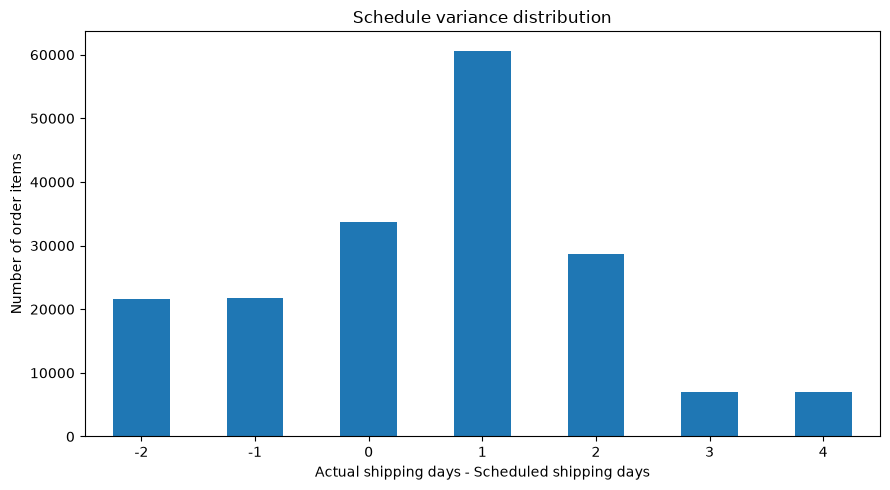

In [6]:
#distribusi variance

variance_counts = (
    df["schedule_variance_days"].value_counts().sort_index()
)
display(variance_counts.rename_axis("variance_days").reset_index(name="item_count"))

plt.figure(figsize=(9, 5))
variance_counts.plot(kind="bar")

plt.title("Schedule variance distribution")
plt.xlabel("Actual shipping days - Scheduled shipping days")
plt.ylabel("Number of order items")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# item late analysis

delayed_items = df.loc[df["delivery_timing"]=="Delayed"].copy()

delayed_summary = delayed_items["schedule_variance_days"].describe(percentiles=[0.25,0.50,0.75,0.90,0.95]).to_frame("delayed_variance_days")
display(delayed_summary)

,delayed_variance_days
count,98977.000000
mean,1.618184
std,0.882527
min,1.000000
25%,1.000000
50%,1.000000
75%,2.000000
90%,3.000000
95%,4.000000
max,4.000000


In [8]:
#validate rule clasification

variance = df["schedule_variance_days"]
timing = df["delivery_timing"]

validation = pd.DataFrame({
    "check": [
        "delayed but variance <= 0",
        "not delayed but variance > 0",
        "canceled but variance is null",
        "unexpected delivery_timing"
    ],
    "count":[
        ((timing == "Delayed") & (variance <= 0)).sum(),
        ((timing == "Not delayed") & (variance > 0)).sum(),
        ((timing == "Canceled") & variance.isna()).sum(),
        (~timing.isin(["Delayed", "Not delayed", "Canceled"])).sum()
    ]
})

display(validation)

,check,count
0,delayed but variance <= 0,0
1,not delayed but variance > 0,0
2,canceled but variance is null,0
3,unexpected delivery_timing,0


3. Segment Comparison & Diagnosis

In [9]:
#delivery_performance by shipping mode

shipping_analysis = df[df["delivery_timing"].isin(["Delayed", "Not delayed", "Canceled"])].copy()

shipping_summary = (
    shipping_analysis.groupby("Shipping Mode")
    .agg(total_items=("Order Item Id", "count"),
        delayed_items=("delivery_timing",lambda s: (s == "Delayed").sum()),
        on_time_or_early_items=("delivery_timing",lambda s: (s== "Not delayed").sum()),
        canceled_items=("delivery_timing",lambda s: (s == "Canceled").sum())
    ).reset_index()
)
eligible_items = (shipping_summary["delayed_items"]+shipping_summary["on_time_or_early_items"])
shipping_summary["delay_rate_pct"] = (shipping_summary["delayed_items"] / eligible_items * 100)
shipping_summary["cancellation_rate_pct"] = (shipping_summary["canceled_items"]/shipping_summary["total_items"]*100)
shipping_summary = shipping_summary.sort_values("delay_rate_pct",ascending=False)

display(shipping_summary)

,Shipping Mode,total_items,delayed_items,on_time_or_early_items,canceled_items,delay_rate_pct,cancellation_rate_pct
0,First Class,27814,26513,0,1301,100.000000,4.677501
2,Second Class,35216,26987,6819,1410,79.829024,4.003862
1,Same Day,9737,4454,4839,444,47.928548,4.559926
3,Standard Class,107752,41023,62130,4599,39.769081,4.268134


In [10]:
# checking variance per shipping

shipping_diagnostic = (
    shipping_analysis.groupby("Shipping Mode").agg(
        avg_actual_days = ("Days for shipping (real)", "mean"),
        avg_scheduled_days = ("Days for shipment (scheduled)", "mean"),
        min_variance = ("schedule_variance_days","min"),
        max_variance = ("schedule_variance_days", "max"),
        variance_zero_or_negative = (
            "schedule_variance_days",
            lambda s: (s <= 0).sum()
        )
    ).reset_index()
)

display(shipping_diagnostic.round(2))

,Shipping Mode,avg_actual_days,avg_scheduled_days,min_variance,max_variance,variance_zero_or_negative
0,First Class,2.00,1.0,1,1,0
1,Same Day,0.48,0.0,0,1,5080
2,Second Class,3.99,2.0,0,4,7138
3,Standard Class,4.00,4.0,-2,2,64901


In [11]:
#delivery performance by market 

market_summary = (
    shipping_analysis.groupby("Market").agg(
        total_items=("Order Item Id", "count"),
        delayed_items = ("delivery_timing", lambda s: (s == "Delayed").sum()),
        on_time_or_early_items=("delivery_timing", lambda s: (s == "Not delayed").sum()),
        canceled_items = ("delivery_timing", lambda s : (s =="Canceled").sum())
    ).reset_index()
)

market_summary["eligible_items"] = (
    market_summary["delayed_items"]+market_summary["on_time_or_early_items"]
)

market_summary["delay_rate_pct"]=(
    market_summary["delayed_items"] /
    market_summary["eligible_items"]*100)

market_summary["cancellation_rate_pct"] = (
    market_summary["canceled_items"]/market_summary["total_items"] * 100
)

display(
    market_summary.sort_values("delay_rate_pct", ascending=False).round(2)
)

,Market,total_items,delayed_items,on_time_or_early_items,canceled_items,eligible_items,delay_rate_pct,cancellation_rate_pct
1,Europe,50252,27743,20347,2162,48090,57.69,4.30
4,USCA,25799,14138,10489,1172,24627,57.41,4.54
3,Pacific Asia,41260,22712,16873,1675,39585,57.38,4.06
2,LATAM,51594,28044,21265,2285,49309,56.87,4.43
0,Africa,11614,6340,4814,460,11154,56.84,3.96


In [12]:
# delivery performance by order region 

region_summary = (
    shipping_analysis.groupby("Order Region")
    .agg(
        total_items = ("Order Item Id", "count"),
        delayed_items = ("delivery_timing",lambda s: (s == "Delayed").sum()),
        on_time_or_early_items=("delivery_timing",lambda s: (s == "Not delayed").sum()),
        canceled_items=("delivery_timing",lambda s: (s == "Canceled").sum())
    ).reset_index()
)

region_summary["eligible_items"] = (
    region_summary["delayed_items"]+ region_summary["on_time_or_early_items"]
)
region_summary["delay_rate_pct"] = (
    region_summary["delayed_items"] / region_summary["eligible_items"]* 100
)
region_summary["cancellation_rate_pct"] = (region_summary["canceled_items"]/ region_summary["total_items"]* 100)
display(
    region_summary.sort_values("delay_rate_pct", ascending=False).round(2)
)


,Order Region,total_items,delayed_items,on_time_or_early_items,canceled_items,eligible_items,delay_rate_pct,cancellation_rate_pct
2,Central Africa,1677,972,644,61,1616,60.15,3.64
22,Western Europe,27109,15140,10727,1242,25867,58.53,4.58
14,South of USA,4045,2256,1599,190,3855,58.52,4.70
13,South Asia,7731,4350,3105,276,7455,58.35,3.57
5,East Africa,1852,1036,745,71,1781,58.17,3.83
6,East of USA,6915,3849,2768,298,6617,58.17,4.31
15,Southeast Asia,9539,5297,3839,403,9136,57.98,4.22
20,West Asia,6009,3322,2424,263,5746,57.81,4.38
8,Eastern Europe,3920,2182,1603,135,3785,57.65,3.44
18,US Center,5887,3252,2401,234,5653,57.53,3.97


4. time series analysis

In [ ]:
#monthly summary

monthly_analysis = df[
    df["delivery_timing"].isin(
        ["Delayed", "Not delayed", "Canceled"]
    )
].copy()

monthly_analysis["order_year_month"] = pd.to_datetime(monthly_analysis["order_year_month"].astype(str))

monthly_summary = (
    monthly_analysis
    .groupby("order_year_month")
    .agg(
        total_items=("Order Item Id", "count"),
        delayed_items=("delivery_timing",lambda s: (s == "Delayed").sum()),
        on_time_or_early_items=("delivery_timing",lambda s: (s == "Not delayed").sum()),
        canceled_items=("delivery_timing",lambda s: (s == "Canceled").sum())
    ).reset_index()
)

monthly_summary["eligible_items"] = (monthly_summary["delayed_items"]+ monthly_summary["on_time_or_early_items"])
monthly_summary["delay_rate_pct"] = (monthly_summary["delayed_items"]/ monthly_summary["eligible_items"]* 100)
monthly_summary["cancellation_rate_pct"] = (monthly_summary["canceled_items"]/ monthly_summary["total_items"]* 100)
display(monthly_summary.round(2))

/tmp/ipykernel_4943/359987867.py:28: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(monthly_summary.round(2))


,order_year_month,total_items,delayed_items,on_time_or_early_items,canceled_items,eligible_items,delay_rate_pct,cancellation_rate_pct
0,2015-01-01,5322,2880,2234,208,5114,56.32,3.91
1,2015-02-01,4729,2594,1893,242,4487,57.81,5.12
2,2015-03-01,5362,2936,2191,235,5127,57.27,4.38
3,2015-04-01,5126,2760,2155,211,4915,56.15,4.12
4,2015-05-01,5357,2951,2136,270,5087,58.01,5.04
5,2015-06-01,5134,2778,2130,226,4908,56.60,4.40
6,2015-07-01,5299,2939,2185,175,5124,57.36,3.30
7,2015-08-01,5273,2936,2089,248,5025,58.43,4.70
8,2015-09-01,5140,2914,2012,214,4926,59.16,4.16
9,2015-10-01,5302,2906,2167,229,5073,57.28,4.32


<function matplotlib.pyplot.show(close=None, block=None)>

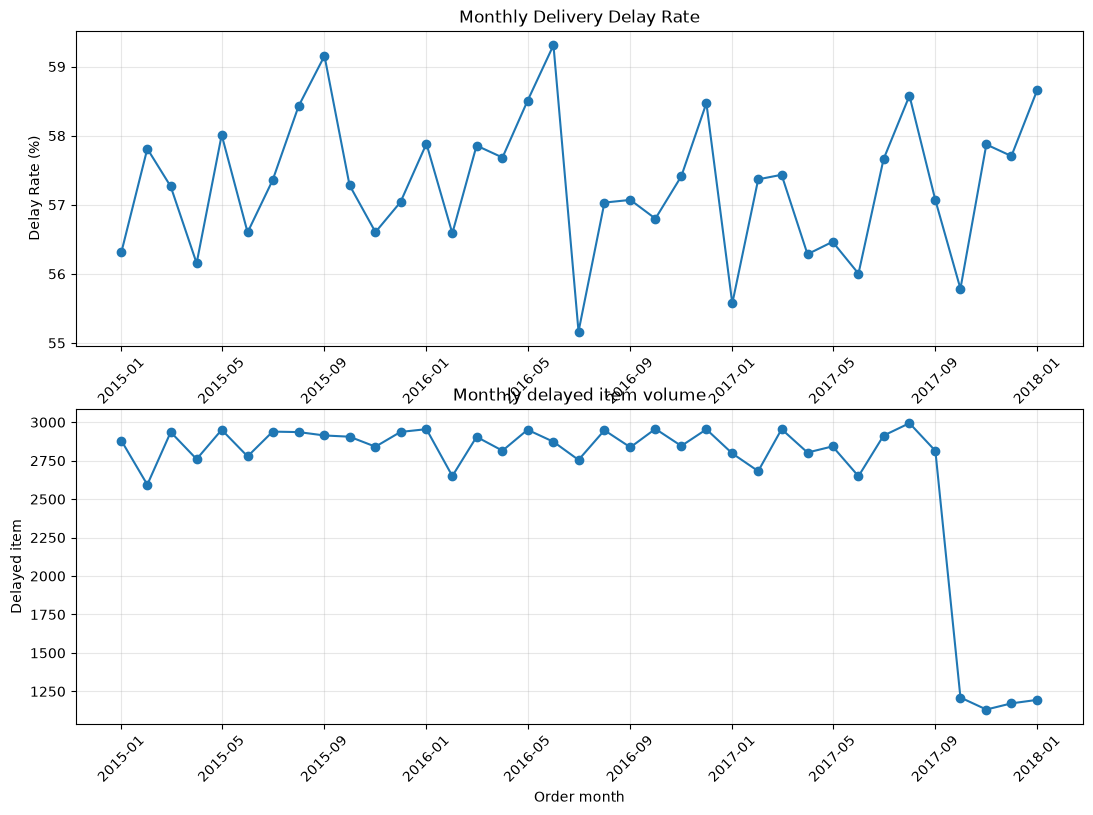

In [14]:
fig, axes= plt.subplots(2,1 , figsize=(13,9))

axes[0].plot(
    monthly_summary["order_year_month"],
    monthly_summary["delay_rate_pct"],
    marker="o"
)

axes[0].set_title("Monthly Delivery Delay Rate")
axes[0].set_ylabel("Delay Rate (%)")
axes[0].set_xlabel("Order Month")
axes[0].tick_params(axis="x", rotation=45)
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    monthly_summary["order_year_month"],
    monthly_summary["delayed_items"],
    marker="o"
)

axes[1].set_title("Monthly delayed item volume")
axes[1].set_ylabel("Delayed item")
axes[1].set_xlabel("Order month")
axes[1].tick_params(axis="x", rotation=45)
axes[1].grid(True, alpha=0.3)

plt.tight_layout
plt.show

In [ ]:
#Check the date range

print("earlier order date:", df["order_date"].min())
print("latest order date:", df["order_date"].max())

year_summary = (
    df.groupby("order_year")
    .agg(
        total_items=("Order Item Id", "count"),
        first_order_date=("order_date", "min"),
        last_order_date=("order_date", "max"),
        active_months=("order_year_month", "nunique")
    ).reset_index()
)
display(year_summary)

earlier order date: 2015-01-01 00:00:00
latest order date: 2018-01-31 00:00:00


,order_year,total_items,first_order_date,last_order_date,active_months
0,2015,62650,2015-01-01 00:00:00,2015-12-31 00:00:00,12
1,2016,62550,2016-01-01 00:00:00,2016-12-31 00:00:00,12
2,2017,53196,2017-01-01 00:00:00,2017-12-31 00:00:00,12
3,2018,2123,2018-01-01 00:00:00,2018-01-31 00:00:00,1


In [ ]:
df["order_month_start"] = (pd.to_datetime(df["order_date"]).dt.to_period("M").dt.to_timestamp())

monthly_volume_check = (
    df.groupby("order_month_start")
        .agg(
        total_items=("Order Item Id", "count"),
        first_order_date=("order_date", "min"),
        last_order_date=("order_date", "max")
    ).reset_index()
)

display(monthly_volume_check.tail(8))

,order_month_start,total_items,first_order_date,last_order_date
29,2017-06-01,4951,2017-06-01 00:00:00,2017-06-30 00:00:00
30,2017-07-01,5318,2017-07-01 00:00:00,2017-07-31 00:00:00
31,2017-08-01,5305,2017-08-01 00:00:00,2017-08-31 00:00:00
32,2017-09-01,5189,2017-09-01 00:00:00,2017-09-30 00:00:00
33,2017-10-01,2255,2017-10-01 00:00:00,2017-10-31 00:00:00
34,2017-11-01,2055,2017-11-01 00:00:00,2017-11-30 00:00:00
35,2017-12-01,2124,2017-12-01 00:00:00,2017-12-31 00:00:00
36,2018-01-01,2123,2018-01-01 00:00:00,2018-01-31 00:00:00


5. Profitability analysis

In [ ]:
# grain profit checking
profit_grain_check = (
    df.groupby("Order Id")
    .agg(
        item_rows = ("Order Item Id", "count"),
        unique_profit_values = ("Order Profit Per Order", "nunique"),
        profit_values = ("Order Profit Per Order", "first"),
        sum_profit_rows = ("Order Profit Per Order", "sum")
    ).reset_index()
)

display(profit_grain_check.head(10))

print("order with multiple profit values:", (profit_grain_check["unique_profit_values"] > 1).sum())

print("order with repeated profit values:", (profit_grain_check["item_rows"] > profit_grain_check["unique_profit_values"]).sum())

,Order Id,item_rows,unique_profit_values,profit_values,sum_profit_rows
0,1,1,1,88.790001,88.790001
1,2,3,3,91.180000,195.900002
2,4,4,4,4.100000,124.090000
3,5,5,5,34.939999,390.089995
4,7,3,3,120.949997,203.929998
5,8,4,4,-131.149994,-39.669994
6,9,3,3,96.000000,119.599999
7,10,5,5,28.730000,93.679999
8,11,5,5,16.799999,273.000000
9,12,5,5,23.490000,406.860010


order with multiple profit values: 45902
order with repeated profit values: 60


In [18]:
# profit consistency relative to shipment status

order_status_check = (
    df.groupby("Order Id")
    .agg(
        item_rows=("Order Item Id", "count"),
        unique_delivery_status=("delivery_timing", "nunique"),
        unique_profit_values=("Order Profit Per Order", "nunique")
    ).reset_index()
)


display(order_status_check[
        (order_status_check["unique_delivery_status"] > 1) |
        (order_status_check["unique_profit_values"] > 1)].head(10)
)

print("order with mixed delivery timing: ", (order_status_check["unique_delivery_status"] > 1).sum())

,Order Id,item_rows,unique_delivery_status,unique_profit_values
1,2,3,1,3
2,4,4,1,4
3,5,5,1,5
4,7,3,1,3
5,8,4,1,4
6,9,3,1,3
7,10,5,1,5
8,11,5,1,5
9,12,5,1,5
11,14,3,1,3


order with mixed delivery timing:  0


In [ ]:
#profit comparison based on delivery timing
profit_by_timing = (
    df.groupby("delivery_timing")
    .agg(
        total_items=("Order Item Id", "count"),
        total_profit=("Order Profit Per Order", "sum"),
        avg_profit_per_item=("Order Profit Per Order", "mean"),
        median_profit_per_item=("Order Profit Per Order", "median"),
        negative_profit_items=(
            "Order Profit Per Order",lambda s: (s < 0).sum()
        )
    ).reset_index()
)

profit_by_timing["negative_profit_pct"] = (profit_by_timing["negative_profit_items"]/ profit_by_timing["total_items"] * 100)

display(profit_by_timing.sort_values("avg_profit_per_item").round(2))


,delivery_timing,total_items,total_profit,avg_profit_per_item,median_profit_per_item,negative_profit_items,negative_profit_pct
0,Canceled,7754,160482.34,20.70,31.57,1489,19.20
1,Delayed,98977,2140051.68,21.62,31.43,18553,18.74
2,Not delayed,73788,1666368.95,22.58,31.68,13742,18.62


<function matplotlib.pyplot.show(close=None, block=None)>

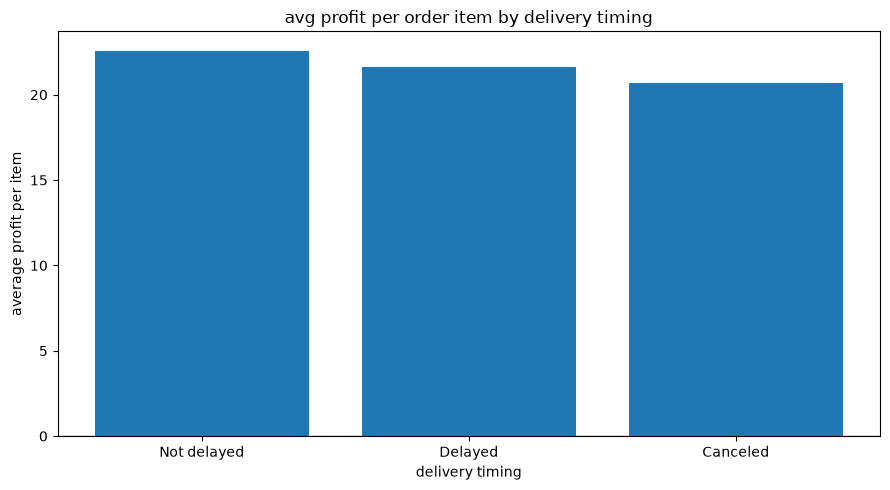

In [20]:
profit_plot = profit_by_timing.sort_values(
    "avg_profit_per_item", ascending=False
)

plt.figure(figsize=(9, 5))
plt.bar(
    profit_plot["delivery_timing"],
    profit_plot["avg_profit_per_item"]
)

plt.title("avg profit per order item by delivery timing")
plt.xlabel("delivery timing")
plt.ylabel("average profit per item")
plt.axhline(0, linewidth=1)
plt.tight_layout()
plt.show

In [ ]:
# negative profit validation
profit_by_category = (
    df.groupby(["Category Name", "delivery_timing"])
    .agg(
        total_items=("Order Item Id", "count"),
        avg_profit_per_item=("Order Profit Per Order", "mean"),
        negative_profit_items=("Order Profit Per Order",lambda s: (s < 0).sum())
    ).reset_index()
)
profit_by_category["negative_profit_pct"] = (profit_by_category["negative_profit_items"]/ profit_by_category["total_items"]* 100)
display(profit_by_category.sort_values(["Category Name", "delivery_timing"]).round(2))


,Category Name,delivery_timing,total_items,avg_profit_per_item,negative_profit_items,negative_profit_pct
0,Accessories,Canceled,83,10.74,15,18.07
1,Accessories,Delayed,1014,9.32,180,17.75
2,Accessories,Not delayed,683,9.22,124,18.16
3,As Seen on TV!,Canceled,2,-367.04,1,50.00
4,As Seen on TV!,Delayed,39,-2.73,11,28.21
...,...,...,...,...,...,...
144,Women's Clothing,Delayed,367,31.57,58,15.80
145,Women's Clothing,Not delayed,264,27.05,47,17.80
146,Women's Golf Clubs,Canceled,11,-31.24,3,27.27
147,Women's Golf Clubs,Delayed,97,36.90,16,16.49


In [ ]:
#lowest average profit
category_profit_summary = (
    df.groupby("Category Name")
    .agg(
        total_items=("Order Item Id", "count"),
        total_profit=("Order Profit Per Order", "sum"),
        avg_profit_per_item=("Order Profit Per Order", "mean"),
        negative_profit_items=("Order Profit Per Order",lambda s: (s < 0).sum())
    ).reset_index()
)

category_profit_summary["negative_profit_pct"] = (category_profit_summary["negative_profit_items"]/ category_profit_summary["total_items"]* 100)

display(category_profit_summary.sort_values("avg_profit_per_item").round(2))


,Category Name,total_items,total_profit,avg_profit_per_item,negative_profit_items,negative_profit_pct
7,CDs,271,383.85,1.42,36,13.28
43,Toys,529,900.71,1.70,82,15.50
5,Books,405,883.01,2.18,78,19.26
41,Strength Training,111,332.31,2.99,18,16.22
45,Video Games,838,2717.52,3.24,181,21.60
24,Golf Balls,1475,8342.67,5.66,263,17.83
37,Pet Supplies,492,3589.26,7.30,104,21.14
2,Baby,207,1525.03,7.37,34,16.43
22,Golf Apparel,441,3496.31,7.93,88,19.95
44,Trade-In,974,7915.37,8.13,177,18.17


In [23]:

category_timing_comparison = (
    df.groupby(["Category Name", "delivery_timing"])
    .agg(
        total_items=("Order Item Id", "count"),
        avg_profit=("Order Profit Per Order", "mean")
    ).reset_index()
)


category_counts = (
    category_timing_comparison
    .pivot(
        index="Category Name",
        columns="delivery_timing",
        values="total_items"
    )
)

required_statuses = ["Delayed", "Not delayed", "Canceled"]

eligible_categories = category_counts[category_counts[required_statuses].ge(100).all(axis=1)].index

comparison = category_timing_comparison[category_timing_comparison["Category Name"].isin(eligible_categories)]

comparison_pivot = comparison.pivot(index="Category Name",columns="delivery_timing",values="avg_profit")

comparison_pivot["delayed_vs_not_delayed_diff"] = (comparison_pivot["Delayed"]- comparison_pivot["Not delayed"])

display(comparison_pivot.sort_values("delayed_vs_not_delayed_diff").round(2))


delivery_timing,Canceled,Delayed,Not delayed,delayed_vs_not_delayed_diff
Category Name,,,,
Camping & Hiking,30.70,29.18,33.76,-4.58
Cardio Equipment,37.15,29.01,32.20,-3.19
Fishing,33.76,43.05,45.48,-2.43
Women's Apparel,17.50,15.93,17.54,-1.61
Indoor/Outdoor Games,19.38,16.09,16.75,-0.66
Men's Footwear,15.45,13.74,14.23,-0.49
Cleats,19.29,19.99,20.45,-0.46
Electronics,18.04,12.96,12.41,0.55
Water Sports,24.49,21.07,20.35,0.72


In [ ]:
# Profit summary by shipment status
profit_comparison = (
    df.groupby("delivery_timing")
    .agg(
        total_items=("Order Item Id", "count"),
        avg_profit=("Order Profit Per Order", "mean"),
        median_profit=("Order Profit Per Order", "median"),
        negative_profit_items=(
            "Order Profit Per Order",lambda x: (x < 0).sum()
        )
    ).reset_index()
)

profit_comparison["negative_profit_pct"] = (profit_comparison["negative_profit_items"]/ profit_comparison["total_items"] * 100).round(2)

display(profit_comparison.round(2))

,delivery_timing,total_items,avg_profit,median_profit,negative_profit_items,negative_profit_pct
0,Canceled,7754,20.70,31.57,1489,19.20
1,Delayed,98977,21.62,31.43,18553,18.74
2,Not delayed,73788,22.58,31.68,13742,18.62


In [ ]:
# average profit difference between Delayed and Not delayed items
category_profit = (
    df[df["delivery_timing"].isin(["Delayed", "Not delayed"])]
    .groupby(["Category Name", "delivery_timing"])
    .agg(
        total_items=("Order Item Id", "count"),
        avg_profit=("Order Profit Per Order", "mean")
    ).reset_index()
)

category_comparison = category_profit.pivot(
    index="Category Name",
    columns="delivery_timing",
    values="avg_profit"
)

category_comparison["profit_difference"] = (category_comparison["Delayed"]- category_comparison["Not delayed"])

display(category_comparison.sort_values("profit_difference").round(2))

delivery_timing,Delayed,Not delayed,profit_difference
Category Name,,,
Basketball,-4.07,76.32,-80.39
As Seen on TV!,-2.73,57.59,-60.32
Strength Training,-22.33,37.17,-59.50
Golf Bags & Carts,23.76,42.75,-18.99
Hunting & Shooting,7.68,22.52,-14.84
Consumer Electronics,25.88,38.56,-12.68
DVDs,11.74,20.64,-8.89
Baby,3.50,11.79,-8.29
Boxing & MMA,17.48,22.97,-5.49


In [ ]:
# Calculate the number of items and average profit per category/status
category_check = (
    df[df["delivery_timing"].isin(["Delayed", "Not delayed"])]
    .groupby(["Category Name", "delivery_timing"])
    .agg(
        item_count=("Order Item Id", "count"),
        avg_profit=("Order Profit Per Order", "mean"),
        median_profit=("Order Profit Per Order", "median"),
        std_profit=("Order Profit Per Order", "std")
    ).reset_index()
)

category_pivot = category_check.pivot(
    index="Category Name",
    columns="delivery_timing",
    values=["item_count", "avg_profit", "median_profit", "std_profit"]
)


category_pivot.columns = [f"{metric}_{timing.replace(' ', '_')}"for metric, timing in category_pivot.columns]
category_pivot = category_pivot.reset_index()
category_pivot = category_pivot[(category_pivot["item_count_Delayed"] >= 100)& (category_pivot["item_count_Not_delayed"] >= 100)].copy()
category_pivot["profit_difference"] = (category_pivot["avg_profit_Delayed"]- category_pivot["avg_profit_Not_delayed"])

display(
    category_pivot.sort_values("profit_difference")
    [[
        "Category Name",
        "item_count_Delayed",
        "item_count_Not_delayed",
        "avg_profit_Delayed",
        "avg_profit_Not_delayed",
        "profit_difference",
        "median_profit_Delayed",
        "median_profit_Not_delayed"
    ]].round(2)
)

,Category Name,item_count_Delayed,item_count_Not_delayed,avg_profit_Delayed,avg_profit_Not_delayed,profit_difference,median_profit_Delayed,median_profit_Not_delayed
29,Hunting & Shooting,247.0,177.0,7.68,22.52,-14.84,12.48,20.47
14,Consumer Electronics,238.0,171.0,25.88,38.56,-12.68,62.17,62.33
16,DVDs,259.0,200.0,11.74,20.64,-8.89,35.05,39.76
6,Boxing & MMA,238.0,164.0,17.48,22.97,-5.49,31.34,30.72
9,Camping & Hiking,7487.0,5670.0,29.18,33.76,-4.58,70.98,72.54
25,Golf Gloves,602.0,427.0,11.57,15.66,-4.09,12.34,12.27
32,Lacrosse,206.0,123.0,11.00,14.88,-3.88,15.30,14.06
28,Hockey,329.0,259.0,8.46,12.30,-3.84,10.47,10.78
36,Music,248.0,169.0,32.27,36.04,-3.76,63.03,61.90
10,Cardio Equipment,6805.0,5143.0,29.01,32.20,-3.19,44.64,46.06


In [ ]:
# Aggregation of delivery performance by month
monthly_delivery = (
    df.groupby("order_year_month")
    .agg(
        total_items=("Order Item Id", "count"),
        delayed_items=("is_delayed", "sum"),
        canceled_items=("is_canceled", "sum"),
        avg_profit=("Order Profit Per Order", "mean")
    ).reset_index()
)

monthly_delivery["delayed_rate"] = (monthly_delivery["delayed_items"]/ monthly_delivery["total_items"] * 100)

monthly_delivery["canceled_rate"] = (monthly_delivery["canceled_items"]/ monthly_delivery["total_items"] * 100)

display(monthly_delivery.head())
display(monthly_delivery.tail())

,order_year_month,total_items,delayed_items,canceled_items,avg_profit,delayed_rate,canceled_rate
0,2015-01,5322,2880,208,20.980973,54.114994,3.908305
1,2015-02,4729,2594,242,20.964403,54.853034,5.117361
2,2015-03,5362,2936,235,21.219360,54.755688,4.382693
3,2015-04,5126,2760,211,21.085384,53.843153,4.116270
4,2015-05,5357,2951,270,20.934833,55.086802,5.040134


,order_year_month,total_items,delayed_items,canceled_items,avg_profit,delayed_rate,canceled_rate
32,2017-09,5189,2814,258,23.600384,54.230102,4.972056
33,2017-10,2255,1210,86,50.309166,53.658537,3.813747
34,2017-11,2055,1132,99,32.988443,55.085158,4.817518
35,2017-12,2124,1172,93,30.997001,55.178908,4.378531
36,2018-01,2123,1195,86,15.940598,56.288271,4.050871


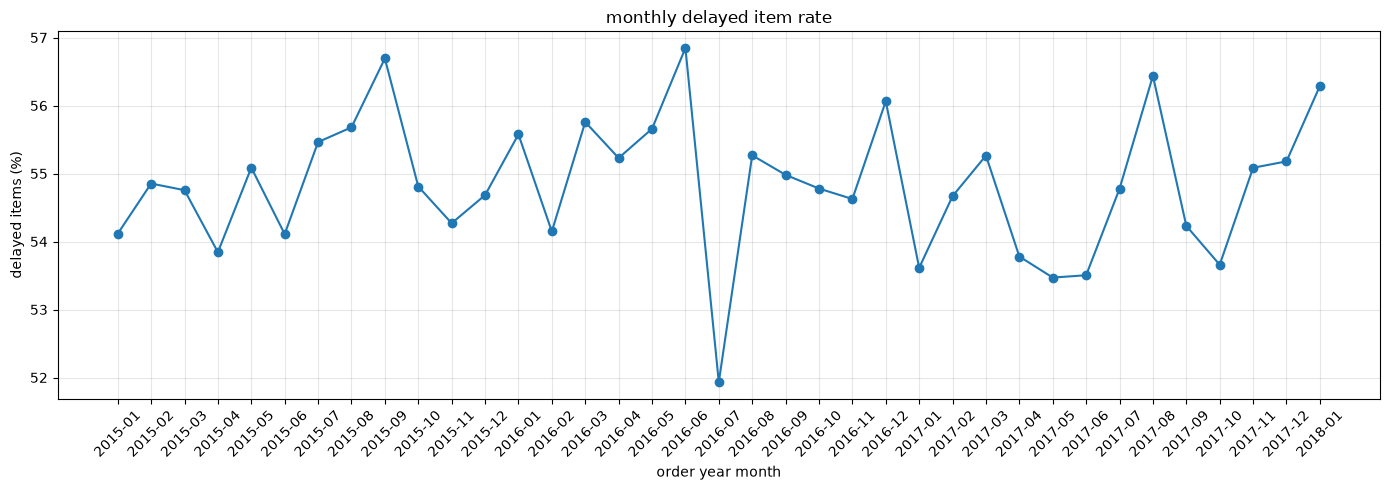

In [ ]:
#visualization of delay trends

plt.figure(figsize=(14,5))

plt.plot(
    monthly_delivery["order_year_month"],
    monthly_delivery["delayed_rate"],
    marker="o"
)

plt.title("monthly delayed item rate")
plt.xlabel("order year month")
plt.ylabel("delayed items (%)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# Month with the highest & lowest delayed rate & # Check for the largest volume change
display(
    monthly_delivery.nlargest(5, "delayed_rate")[
        [
            "order_year_month",
            "total_items",
            "delayed_items",
            "delayed_rate",
            "avg_profit"
        ]
    ]
)
display(
    monthly_delivery.nsmallest(5, "delayed_rate")[
        [
            "order_year_month",
            "total_items",
            "delayed_items",
            "delayed_rate",
            "avg_profit"
        ]
    ]
)
monthly_delivery["item_change_pct"] = (monthly_delivery["total_items"].pct_change() * 100)

display(monthly_delivery.assign(item_change_pct=monthly_delivery["item_change_pct"].round(2)).sort_values("item_change_pct").head(5))

,order_year_month,total_items,delayed_items,delayed_rate,avg_profit
17,2016-06,5054,2873,56.846063,20.616555
8,2015-09,5140,2914,56.692607,22.075475
31,2017-08,5305,2994,56.437323,24.788155
36,2018-01,2123,1195,56.288271,15.940598
23,2016-12,5269,2954,56.063769,19.928391


,order_year_month,total_items,delayed_items,delayed_rate,avg_profit
18,2016-07,5305,2755,51.932139,22.609184
28,2017-05,5317,2843,53.470002,21.631491
29,2017-06,4951,2649,53.504343,22.298382
24,2017-01,5217,2797,53.613188,22.013389
33,2017-10,2255,1210,53.658537,50.309166


,order_year_month,total_items,delayed_items,canceled_items,avg_profit,delayed_rate,canceled_rate,item_change_pct
33,2017-10,2255,1210,86,50.309166,53.658537,3.813747,-56.54
1,2015-02,4729,2594,242,20.964403,54.853034,5.117361,-11.14
34,2017-11,2055,1132,99,32.988443,55.085158,4.817518,-8.87
13,2016-02,4894,2650,211,17.737943,54.147936,4.311402,-7.96
29,2017-06,4951,2649,221,22.298382,53.504343,4.463745,-6.88


In [ ]:
# examining the October 2017 anomaly
period_check = df[df["order_year_month"].isin(["2017-09", "2017-10", "2017-11"])].copy()

category_check = (
    period_check
    .groupby(["order_year_month", "Category Name"])
    .agg(
        total_items=("Order Item Id", "count"),
        avg_profit=("Order Profit Per Order", "mean")
    ).reset_index()
)

top_categories = (
    category_check
    .sort_values(
        ["order_year_month", "total_items"],
        ascending=[True, False]
    ).groupby("order_year_month").head(10)
)

display(top_categories)

,order_year_month,Category Name,total_items,avg_profit
6,2017-09,Cleats,730,27.873397
17,2017-09,Men's Footwear,662,11.914260
24,2017-09,Women's Apparel,641,18.595757
7,2017-09,Fishing,566,43.028198
14,2017-09,Indoor/Outdoor Games,553,19.762423
23,2017-09,Water Sports,512,23.352031
4,2017-09,Camping & Hiking,436,32.874243
5,2017-09,Cardio Equipment,380,21.113368
19,2017-09,Shop By Sport,328,12.816951
15,2017-09,Kids' Golf Clubs,103,35.313106


In [ ]:
# is the decline in volume distributed evenly or concentrated?
category_volume = (category_check.pivot(index="Category Name",columns="order_year_month",values="total_items").fillna(0))

category_volume["change_sep_oct"] = (category_volume["2017-10"]- category_volume["2017-09"])

display(category_volume.sort_values("change_sep_oct").head(10))

order_year_month,2017-09,2017-10,2017-11,change_sep_oct
Category Name,,,,
Cleats,730.0,37.0,0.0,-693.0
Men's Footwear,662.0,32.0,0.0,-630.0
Women's Apparel,641.0,27.0,0.0,-614.0
Fishing,566.0,17.0,0.0,-549.0
Indoor/Outdoor Games,553.0,25.0,0.0,-528.0
Water Sports,512.0,25.0,0.0,-487.0
Camping & Hiking,436.0,15.0,0.0,-421.0
Cardio Equipment,380.0,22.0,0.0,-358.0
Shop By Sport,328.0,9.0,0.0,-319.0


In [ ]:
# temporal data quality validation
monthly_check = (
    df.groupby("order_year_month")
    .agg(
        total_rows=("Order Item Id", "size"),
        unique_orders=("Order Id", "nunique"),
        unique_products=("Product Name", "nunique"),
        unique_categories=("Category Name", "nunique"),
        unique_regions=("Order Region", "nunique"),
        avg_profit=("Order Profit Per Order", "mean")
    ).reset_index()
)

display(monthly_check[monthly_check["order_year_month"].between("2017-07", "2018-01")])

,order_year_month,total_rows,unique_orders,unique_products,unique_categories,unique_regions,avg_profit
30,2017-07,5318,1776,42,24,3,21.253610
31,2017-08,5305,1768,42,24,3,24.788155
32,2017-09,5189,1723,53,26,3,23.600384
33,2017-10,2255,2101,20,20,3,50.309166
34,2017-11,2055,2055,8,8,7,32.988443
35,2017-12,2124,2124,14,14,4,30.997001
36,2018-01,2123,2123,10,10,4,15.940598


In [33]:
region_month_check = (
    df[df["order_year_month"].isin(["2017-09", "2017-10", "2017-11"])]
    .groupby(["order_year_month", "Order Region"])
    .agg(
        total_items=("Order Item Id", "size"),
        unique_orders=("Order Id", "nunique")
    ).reset_index()
)

display(region_month_check.sort_values(["Order Region", "order_year_month"]))

,order_year_month,Order Region,total_items,unique_orders
6,2017-11,Eastern Asia,377,377
0,2017-09,Northern Europe,1104,365
3,2017-10,Northern Europe,460,434
7,2017-11,Northern Europe,168,168
8,2017-11,Oceania,371,371
9,2017-11,South Asia,256,256
10,2017-11,Southeast Asia,369,369
1,2017-09,Southern Europe,1058,360
4,2017-10,Southern Europe,433,422
11,2017-11,Southern Europe,144,144


In [ ]:
# average items per order each month
monthly_grain = (
    df.groupby("order_year_month")
    .agg(
        total_rows=("Order Item Id", "size"),
        unique_items=("Order Item Id", "nunique"),
        unique_orders=("Order Id", "nunique")
    ).reset_index()
)

monthly_grain["rows_per_order"] = (monthly_grain["total_rows"] /monthly_grain["unique_orders"])

monthly_grain["items_per_order"] = (monthly_grain["unique_items"] /monthly_grain["unique_orders"])

display(monthly_grain[monthly_grain["order_year_month"].between("2017-07", "2018-01")].round(2))

,order_year_month,total_rows,unique_items,unique_orders,rows_per_order,items_per_order
30,2017-07,5318,5318,1776,2.99,2.99
31,2017-08,5305,5305,1768,3.00,3.00
32,2017-09,5189,5189,1723,3.01,3.01
33,2017-10,2255,2255,2101,1.07,1.07
34,2017-11,2055,2055,2055,1.00,1.00
35,2017-12,2124,2124,2124,1.00,1.00
36,2018-01,2123,2123,2123,1.00,1.00


In [ ]:
# does the order still contain many items
items_per_order = (
    df.groupby("Order Id")
    .agg(
        item_rows=("Order Item Id", "size"),
        unique_item_ids=("Order Item Id", "nunique"),
        order_month=("order_year_month", "first")
    ).reset_index()
)

order_structure = (
    items_per_order.groupby("order_month")
    .agg(
        unique_orders=("Order Id", "nunique"),
        avg_item_rows=("item_rows", "mean"),
        median_item_rows=("item_rows", "median"),
        orders_with_multiple_rows=(
            "item_rows",
            lambda s: (s > 1).sum()
        )
    ).reset_index()
)

display(order_structure[order_structure["order_month"].between("2017-07", "2018-01")].round(2))

,order_month,unique_orders,avg_item_rows,median_item_rows,orders_with_multiple_rows
30,2017-07,1776,2.99,3.0,1436
31,2017-08,1768,3.00,3.0,1410
32,2017-09,1723,3.01,3.0,1355
33,2017-10,2101,1.07,1.0,63
34,2017-11,2055,1.00,1.0,0
35,2017-12,2124,1.00,1.0,0
36,2018-01,2123,1.00,1.0,0


In [ ]:
# validation of date and completeness of the period
date_check = (
    df.groupby("order_year_month")
    .agg(
        min_order_date=("order_date", "min"),
        max_order_date=("order_date", "max"),
        total_rows=("Order Item Id", "size")
    ).reset_index()
)

display(date_check[date_check["order_year_month"].between("2017-07", "2018-01")])

,order_year_month,min_order_date,max_order_date,total_rows
30,2017-07,2017-07-01 00:00:00,2017-07-31 00:00:00,5318
31,2017-08,2017-08-01 00:00:00,2017-08-31 00:00:00,5305
32,2017-09,2017-09-01 00:00:00,2017-09-30 00:00:00,5189
33,2017-10,2017-10-01 00:00:00,2017-10-31 00:00:00,2255
34,2017-11,2017-11-01 00:00:00,2017-11-30 00:00:00,2055
35,2017-12,2017-12-01 00:00:00,2017-12-31 00:00:00,2124
36,2018-01,2018-01-01 00:00:00,2018-01-31 00:00:00,2123


In [ ]:
# Periksa apakah perubahan jumlah baris per order
# juga terjadi pada karakteristik data lainnya.

monthly_check = (
    df.groupby("order_year_month")
    .agg(
        total_rows=("Order Item Id", "size"),
        unique_orders=("Order Id", "nunique"),
        unique_items=("Order Item Id", "nunique"),
        unique_products=("Product Name", "nunique"),
        unique_categories=("Category Name", "nunique"),
        unique_regions=("Order Region", "nunique"),
        min_order_date=("order_date", "min"),
        max_order_date=("order_date", "max")
    )
    .reset_index()
)

display(monthly_check.tail(12))